# Conditional Flow Matching with Learned Embeddings

In [19]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [4]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


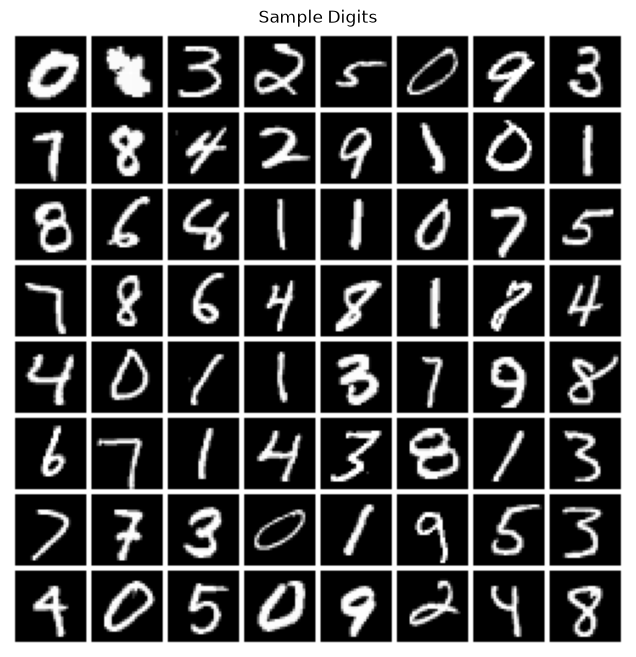

In [5]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

### Learning conditional embeddings

In [ ]:
class CondFlow(nn.Module):
    def __init__(self, dim: int = 784, h: int = 64, c_dim: int = 2):
        super().__init__()
        self.class_emb = nn.Embedding(10, c_dim)
        self.encoder = nn.Sequential(
            nn.Linear(dim+c_dim+1, h),
            nn.ReLU(),
            nn.Linear(h, h),
        )
        self.decoder = nn.Sequential(
            nn.Linear(h, h),
            nn.ReLU(),
            nn.Linear(h, dim),
            # nn.Sigmoid()
        )
    
    def forward(self, t: Tensor, c: Tensor, x_t: Tensor ) -> Tensor:
        c_emb = self.class_emb(c)
        inp = torch.cat((x_t, c_emb, t), 1)
        z = self.encoder(inp)
        return self.decoder(z)
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor, c: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t=x_t + self(x_t=x_t, t=t_start, c=c)*dt/2, t=t_start + dt/2, c=c)
        # return x_t + dt * self(x_t=x_t + self(x_t=x_t, t=t_start, c=c)*dt/2, t=(t_start + t_end)/2, c=c)
        
        # return x_t + (t_end - t_start) * self(t=t_start + (t_end - t_start) / 2, c=c, x_t= x_t + self(c=c, x_t=x_t, t=t_start) * (t_end - t_start) / 2)

In [35]:
def train_cond(flow, train_loader, n_epochs=50, lr=1e-3, sigma_noise=0.1, device=device):
    losses = []
    opt = torch.optim.Adam(flow.parameters(), lr=lr)
    for e in range(n_epochs):
        current_loss = 0.0
        for i, (x, c) in enumerate(train_loader):
            x_1 = x.view(-1, 784).to(device)
            c = c.to(device)

            t = torch.rand(x.shape[0], 1, device=x_1.device)
            x_0 = torch.randn_like(x_1)*sigma_noise + 0.5
            dx_t = x_1 - x_0
            x_t = (1-t)*x_0 + t * x_1
            flow_pred = flow(t=t, c=c, x_t=x_t)

            loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
            loss.backward()
            opt.step()
            opt.zero_grad()

            current_loss += loss.item()
        avg_loss = current_loss / len(train_loader)
        losses.append(avg_loss)

    return losses

In [9]:
N_EPOCHS = 100

cond_flow = CondFlow(h=512).to(device)
opt = torch.optim.Adam(cond_flow.parameters(), lr=1e-3)
losses = []
preds = []
for e in range(N_EPOCHS):
    tot_loss = 0
    n = 0
    for i, (x, l) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)
        l = l.to(device)

        t = torch.rand(x.shape[0], 1, device=x_1.device)
        x_0 = torch.randn_like(x_1)*0.2 + 0.5
        dx_t = x_1 - x_0
        x_t = (1-t)*x_0 + t * x_1
        flow_pred = cond_flow(x_t=x_t, t=t, c=l)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        tot_loss += loss.item()
        n+=1
        opt.step()
        opt.zero_grad()

        if i % 200 == 0:
            print(f'Epoch: {e}, Iter: {i}, Loss: {loss.item():.4f}')
    preds.append(flow_pred[0].cpu().detach().numpy())
    losses.append(tot_loss/n)

Epoch: 0, Iter: 0, Loss: 213.4617
Epoch: 0, Iter: 200, Loss: 65.5785
Epoch: 0, Iter: 400, Loss: 59.2624
Epoch: 1, Iter: 0, Loss: 57.8988
Epoch: 1, Iter: 200, Loss: 53.4376
Epoch: 1, Iter: 400, Loss: 53.6751
Epoch: 2, Iter: 0, Loss: 53.2285
Epoch: 2, Iter: 200, Loss: 51.8720
Epoch: 2, Iter: 400, Loss: 50.4598
Epoch: 3, Iter: 0, Loss: 49.4674
Epoch: 3, Iter: 200, Loss: 52.5484
Epoch: 3, Iter: 400, Loss: 50.9218
Epoch: 4, Iter: 0, Loss: 49.5104
Epoch: 4, Iter: 200, Loss: 49.5882
Epoch: 4, Iter: 400, Loss: 48.9818
Epoch: 5, Iter: 0, Loss: 48.2329
Epoch: 5, Iter: 200, Loss: 49.5853
Epoch: 5, Iter: 400, Loss: 49.0465
Epoch: 6, Iter: 0, Loss: 50.2110
Epoch: 6, Iter: 200, Loss: 48.5714
Epoch: 6, Iter: 400, Loss: 49.5155
Epoch: 7, Iter: 0, Loss: 47.3378
Epoch: 7, Iter: 200, Loss: 49.6651
Epoch: 7, Iter: 400, Loss: 47.7826
Epoch: 8, Iter: 0, Loss: 49.4981
Epoch: 8, Iter: 200, Loss: 47.3985
Epoch: 8, Iter: 400, Loss: 48.2167
Epoch: 9, Iter: 0, Loss: 47.3736
Epoch: 9, Iter: 200, Loss: 48.8963
Epoc

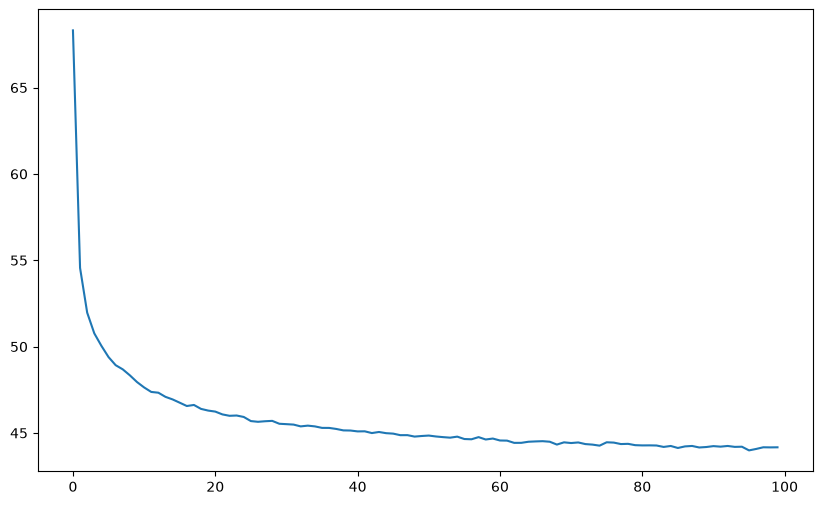

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(losses)
plt.show();

In [11]:
preds = [torch.Tensor(pred) for pred in preds]

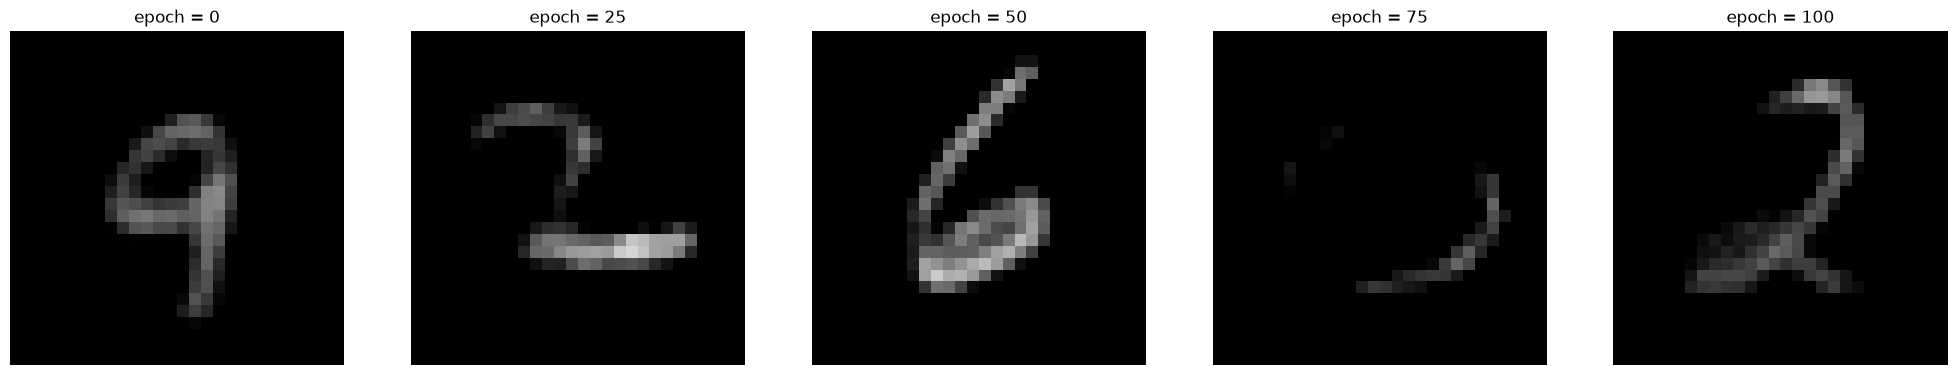

In [12]:

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(preds[0].view(-1, 1, 28, 28), nrow=2, ax=ax[0])
ax[0].set_title('epoch = 0')
ax[1] = show_samples(preds[25].view(-1, 1, 28, 28), nrow=2, ax=ax[1])
ax[1].set_title('epoch = 25')
ax[2] = show_samples(preds[50].view(-1, 1, 28, 28), nrow=2, ax=ax[2])
ax[2].set_title('epoch = 50')
ax[3] = show_samples(preds[75].view(-1, 1, 28, 28), nrow=2, ax=ax[3])
ax[3].set_title('epoch = 75')
ax[4] = show_samples(preds[-1].view(-1, 1, 28, 28), nrow=2, ax=ax[4])
ax[4].set_title('epoch = 100')

plt.show()

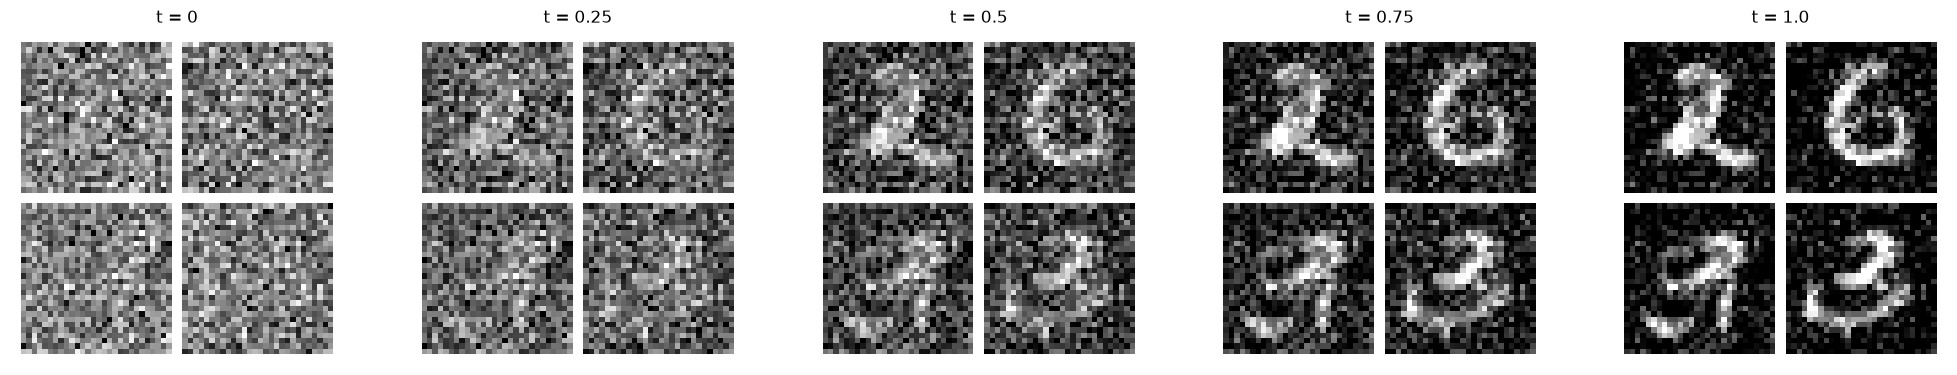

In [13]:
x = torch.randn(6, 784).to(device)*0.2 + 0.5
l = torch.randint(10, (6,)).to(device)
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = cond_flow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device), c=l)
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(states[0].view(-1, 1, 28, 28), nrow=2, ax=ax[0])
ax[0].set_title('t = 0')
ax[1] = show_samples(states[int(n_steps*0.25)].view(-1, 1, 28, 28), nrow=2, ax=ax[1])
ax[1].set_title('t = 0.25')
ax[2] = show_samples(states[int(n_steps*0.5)].view(-1, 1, 28, 28), nrow=2, ax=ax[2])
ax[2].set_title('t = 0.5')
ax[3] = show_samples(states[int(n_steps*0.75)].view(-1, 1, 28, 28), nrow=2, ax=ax[3])
ax[3].set_title('t = 0.75')
ax[4] = show_samples(states[-1].view(-1, 1, 28, 28), nrow=2, ax=ax[4])
ax[4].set_title('t = 1.0')

plt.show()

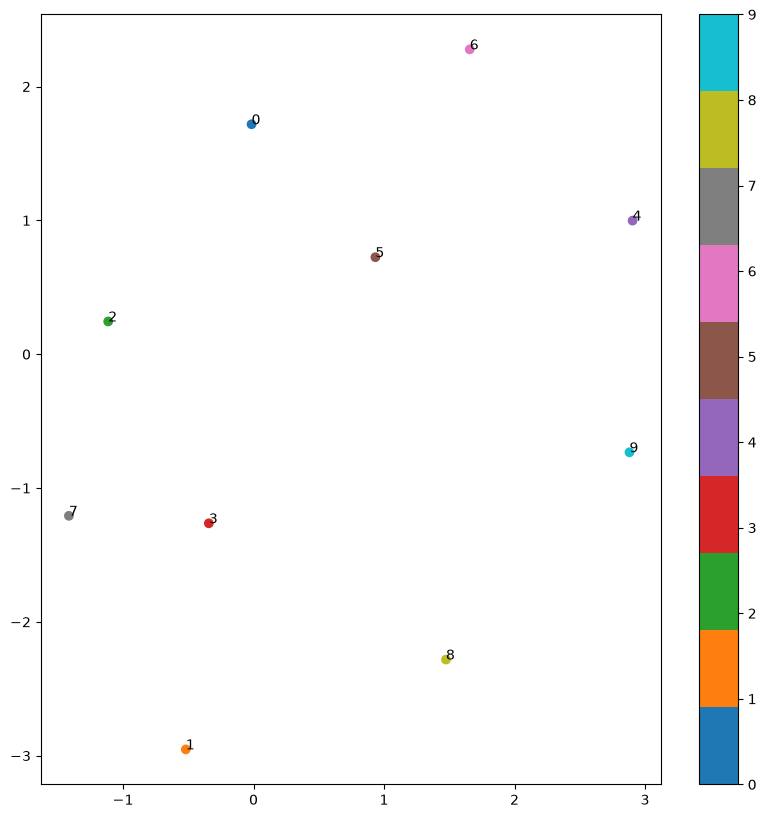

In [14]:
## Visualize embedings
emb = cond_flow.class_emb.weight.data.cpu().numpy()
fig, ax = plt.subplots(figsize=(10, 10))
scatter = ax.scatter(emb[:, 0], emb[:, 1], c=np.arange(10), cmap='tab10')
plt.colorbar(scatter)
for i in range(10):
    ax.annotate(str(i), (emb[i, 0], emb[i, 1]))
plt.show()


